# Challenge 1: Predict the Output

**IBM Quantum | Vishnu Institute of Technology | Qiskit Fall Fest 2026**

For this challenge, students must have a working Python environment with the following packages installed:
- `qiskit` v2.1.0 or newer
- `qiskit-ibm-runtime` v0.40.1 or newer
- `qiskit.visualization`
- `numpy`
- `pylatexenc`

To set up and install the packages above, see the [Install Qiskit](https://quantum.cloud.ibm.com/docs/guides/install-qiskit) guide. In order to run jobs on real quantum computers, you need an IBM Quantum&reg; account (see [Set up your IBM Cloud&reg; account](https://quantum.cloud.ibm.com/docs/guides/cloud-setup)) with an **API key** and an **instance (CRN)**.

In [3]:
# Uncomment and modify this line as needed to install dependencies
#%pip install --upgrade "qiskit[visualization]" qiskit-ibm-runtime numpy pylatexenc

In [4]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram

## Introduction

A quantum circuit can produce different measurement outcomes depending on the gates applied to a qubit. In this challenge we build three one-qubit circuits that all start in $\vert 0\rangle$, **predict** their measurement outcomes before running, execute each for 100 shots on IBM quantum hardware, and compare the prediction with the actual results.

### Gates used

**$X$ gate:** the quantum NOT. It maps $\vert 0\rangle \rightarrow \vert 1\rangle$ and $\vert 1\rangle \rightarrow \vert 0\rangle$.

**Hadamard ($H$) gate:** creates a superposition: $\vert 0\rangle \rightarrow \frac{1}{\sqrt{2}}\left(\vert 0\rangle+\vert 1\rangle\right)$.

**Measurement** collapses the qubit to $0$ or $1$ with probability equal to the squared amplitude of that state.

## Qiskit patterns framework

We follow the Qiskit patterns workflow, a general procedure for solving problems with a quantum computer:

1. **Mapping** the problem to quantum circuits
2. **Optimizing** the circuits for the target hardware
3. **Executing** on the hardware
4. **Post-processing** the results

All circuits below use `measure_all()`, so the results are stored in the classical register called `meas`. Remember that Qiskit uses **little-endian** notation: in a bitstring such as `01`, the rightmost bit is qubit 0.

#### 1. Mapping

We create three circuits, each with exactly 1 qubit (starting in $\vert 0\rangle$) and a measurement.

- **Circuit A:** one $X$ gate
- **Circuit B:** two $X$ gates
- **Circuit C:** one $H$ gate

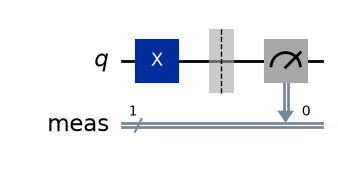

In [5]:
# Circuit A: X gate
qc_a = QuantumCircuit(1)
qc_a.x(0)
qc_a.measure_all()
qc_a.draw("mpl")

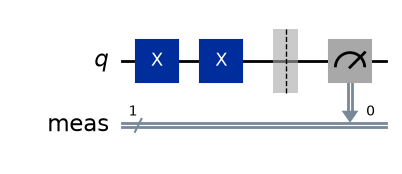

In [6]:
# Circuit B: X gate twice
qc_b = QuantumCircuit(1)
qc_b.x(0)
qc_b.x(0)
qc_b.measure_all()
qc_b.draw("mpl")

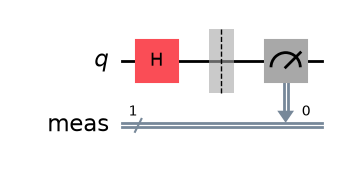

In [7]:
# Circuit C: H gate
qc_c = QuantumCircuit(1)
qc_c.h(0)
qc_c.measure_all()
qc_c.draw("mpl")

### Think before you run: predictions

| Circuit | State before measurement | Prediction |
| :--- | :---: | :--- |
| **A** ($X$) | $\vert 1\rangle$ | `1` in (almost) all 100 shots |
| **B** ($X$, $X$) | $\vert 0\rangle$ | `0` in (almost) all 100 shots, since $X\cdot X = I$ |
| **C** ($H$) | $\frac{1}{\sqrt{2}}(\vert 0\rangle+\vert 1\rangle)$ | about 50 zeros and 50 ones |

- **After one X gate?** The qubit flips to $\vert 1\rangle$.
- **After two X gates?** The second X flips it back to $\vert 0\rangle$.
- **After an H gate?** An equal superposition, so each outcome has probability 0.5.
- **Will Circuit C always produce the same result?** No. Each shot is random, so the counts change from run to run.

#### 2. Optimizing

Next, we optimize the circuits for the quantum hardware using the transpiler. It assigns the logical qubits to physical qubits on the processor and rewrites the gates in terms of the hardware's native gate set. We choose an optimization level from 0 (none) to 3 (highest); see [Set transpiler optimization level](https://quantum.cloud.ibm.com/docs/guides/set-optimization). The transpiled circuit looks different from the logical one we mapped.

In [8]:
# Load the Qiskit Runtime service
from qiskit_ibm_runtime import QiskitRuntimeService

# Syntax for first saving your credentials. Delete these lines after saving them once,
# and never share a notebook that contains your real API key.
QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    instance="<YOUR_INSTANCE_CRN>",
    token="<YOUR_API_KEY>",
    overwrite=True,
    set_as_default=True,
)
service = QiskitRuntimeService(channel="ibm_quantum_platform")

# Load saved credentials (use this line on later runs)
# service = QiskitRuntimeService()

# Use the least busy backend, or uncomment the loading of a specific backend.
backend = service.least_busy(operational=True, simulator=False)
# backend = service.backend("ibm_brisbane")
print(backend.name)

ibm_fez


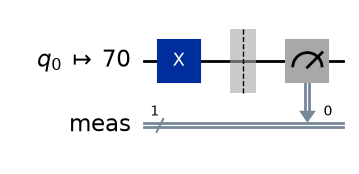

In [9]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)

circuits = [qc_a, qc_b, qc_c]
isa_circuits = pm.run(circuits)

isa_circuits[0].draw("mpl", idle_wires=False)

#### 3. Executing

A "Sampler" is a primitive that samples the possible states resulting from a quantum circuit and collects statistics on what is measured and with what probability. We send **all circuits as a single job** with **100 shots** each.

In [12]:
# Load the Runtime primitive
from qiskit_ibm_runtime.executor_sampler import Sampler

sampler = Sampler(mode=backend)

In [13]:
job = sampler.run(isa_circuits, shots=100)
print("Job ID:", job.job_id())

res = job.result()   # waits until the job finishes
all_counts = [r.data.meas.get_counts() for r in res]
counts_a, counts_b, counts_c = all_counts
print("A:", counts_a)
print("B:", counts_b)
print("C:", counts_c)

Job ID: db5qkho4qg6s73c3rs50
A: {'1': 100}
B: {'0': 100}
C: {'0': 43, '1': 57}


#### 4. Post-processing

Now we view the results as histograms of the 100 shots of each circuit.

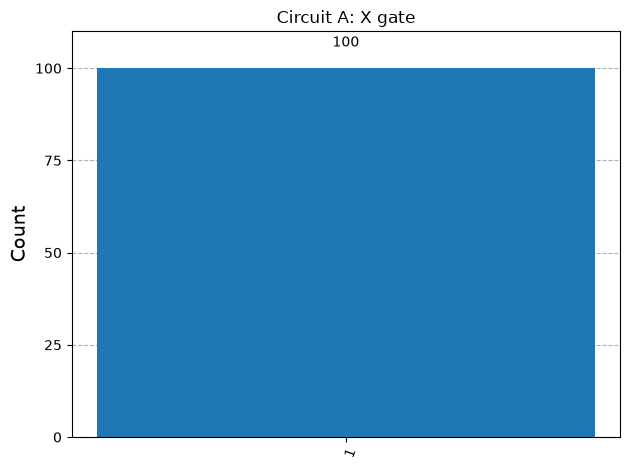

In [14]:
plot_histogram(counts_a, title="Circuit A: X gate")

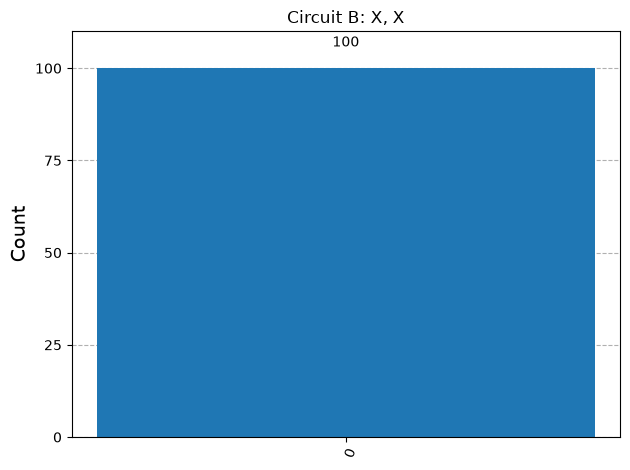

In [15]:
plot_histogram(counts_b, title="Circuit B: X, X")

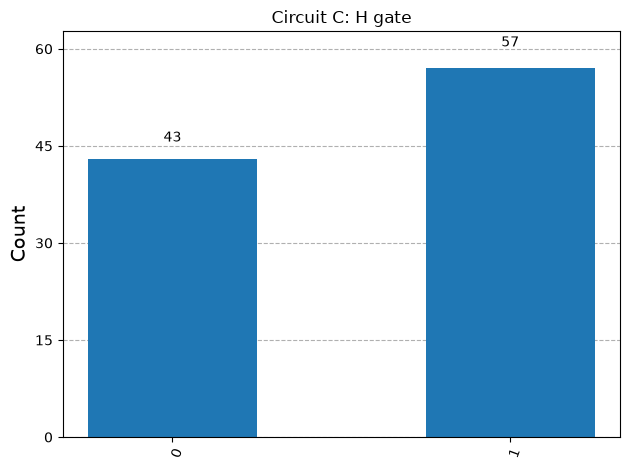

In [16]:
plot_histogram(counts_c, title="Circuit C: H gate")

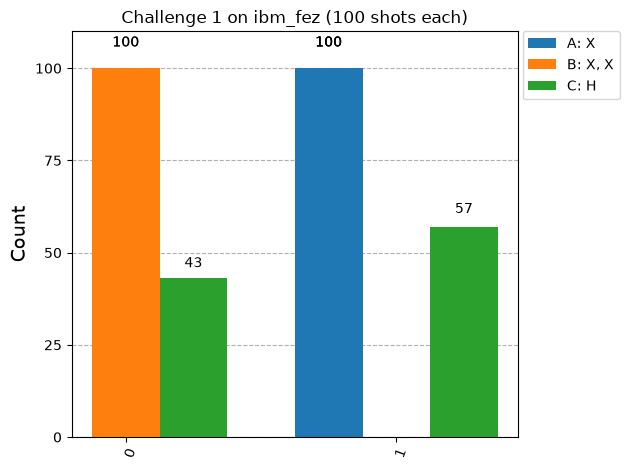

In [17]:
plot_histogram([counts_a, counts_b, counts_c],
               legend=["A: X", "B: X, X", "C: H"],
               title=f"Challenge 1 on {backend.name} (100 shots each)")

### Prediction vs actual results

In [18]:
rows = [("A: X", "~100% '1'", counts_a),
        ("B: X, X", "~100% '0'", counts_b),
        ("C: H", "~50% / ~50%", counts_c)]
print(f"{'Circuit':10s}{'Prediction':16s}{'Actual 0':>10s}{'Actual 1':>10s}")
for name, pred, c in rows:
    print(f"{name:10s}{pred:16s}{c.get('0', 0):>10d}{c.get('1', 0):>10d}")

Circuit   Prediction        Actual 0  Actual 1
A: X      ~100% '1'                0       100
B: X, X   ~100% '0'              100         0
C: H      ~50% / ~50%             43        57


### Comparison of prediction and results

- **Circuit A:** the dominant outcome is `1`, as predicted. One $X$ gate deterministically flips $\vert 0\rangle$ to $\vert 1\rangle$.
- **Circuit B:** the dominant outcome is `0`, as predicted. Two $X$ gates cancel out.
- **Circuit C:** the counts are close to a 50/50 split but not exactly equal, and re-running gives a different split. Unlike A and B, this circuit is probabilistic: the Hadamard gate puts the qubit in superposition, and measurement picks 0 or 1 at random.

An ideal quantum computer would only give the predicted outcomes, but real hardware has noise (gate and readout errors), so a few stray counts are expected.

## Conclusion

### Critical concepts:

- The **$X$ gate** is deterministic: it flips $\vert 0\rangle$ and $\vert 1\rangle$. Applying it twice returns the original state.
- The **Hadamard gate** creates an equal **superposition**, so the measurement outcome is random with probability 0.5 each.
- **Measurement** collapses the state to one classical outcome, and repeating many **shots** reveals the probability distribution.
- Real quantum hardware introduces **noise**, so results deviate slightly from ideal predictions.